# TennisEye feature analysis

Feature analysis of the [TennisEye](https://github.com/hongyang-zhao/TennisEye) dataset
(Zhao et al., IPSN 2019): a racket-handle IMU (accelerometer ±16 g in m/s², gyroscope ±2000 °/s, 100 Hz)
with PlaySight ground truth for stroke type, ball speed (mph) and spin (rpm). 7 players, 2013 shots,
one 1 s window (100 samples) per shot.

**Questions**
1. Where is the ball impact in each window, and what does a typical stroke look like?
2. Which hand-crafted IMU features track outgoing ball speed / spin?
3. How well do those features predict ball speed and stroke type for an **unseen player** (leave-one-subject-out)?

Data comes from `data/tenniseye/*.parquet` (made by `scripts/tenniseye_to_parquet.py`).
The dataset license forbids redistribution, so neither the data nor this notebook's outputs should be published.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import RidgeCV
from sklearn.metrics import confusion_matrix, f1_score, mean_absolute_error
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=RuntimeWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)

DATA = Path("../data/tenniseye")
FS = 100.0
ACC_SAT, GYRO_SAT = 156.0, 1999.0   # sensor full-scale (16 g = 156.9 m/s^2, 2000 deg/s)

shots = pd.read_parquet(DATA / "tenniseye_shots.parquet").sort_values("shot_id").reset_index(drop=True)
samples = pd.read_parquet(DATA / "tenniseye_samples.parquet").sort_values(["shot_id", "sample"])
X = samples[["ax", "ay", "az", "gx", "gy", "gz"]].to_numpy().reshape(len(shots), 100, 6)

# Volleys are rare (33 shots): merge them for modelling
shots["stroke4"] = shots["stroke"].astype(str).replace({"forehand_volley": "volley", "backhand_volley": "volley"})
shots["group"] = np.where(shots.stroke_type == 0, "serve", "groundstroke/volley")
print(X.shape)
shots.head()

(2013, 100, 6)


,shot_id,player_id,player_shot_idx,stroke_type,stroke,out_speed_mph,out_spin_rpm,in_speed_mph,in_spin_rpm,n_samples,stroke4,group
0,0,1,1,1,forehand,61,0,0,0,100,forehand,groundstroke/volley
1,1,1,2,0,serve,75,0,0,0,100,serve,serve
2,2,1,3,0,serve,82,0,0,0,100,serve,serve
3,3,1,4,0,serve,70,0,0,0,100,serve,serve
4,4,1,5,0,serve,93,0,0,0,100,serve,serve


## 1. Dataset overview

stroke,backhand,backhand_volley,forehand,forehand_volley,serve,All
player_id,,,,,,
1,4,0,9,0,36,49
2,69,8,145,5,75,302
3,66,0,70,0,50,186
4,62,1,240,3,0,306
5,158,6,470,10,0,644
6,35,0,83,0,263,381
7,0,0,0,0,145,145
All,394,15,1017,18,569,2013


Label coverage (0 = not recorded by PlaySight):


,out_speed_mph,out_spin_rpm,in_speed_mph,in_spin_rpm
stroke,,,,
backhand,100%,80%,89%,74%
backhand_volley,100%,33%,93%,7%
forehand,100%,83%,79%,67%
forehand_volley,100%,56%,94%,28%
serve,100%,37%,0%,0%


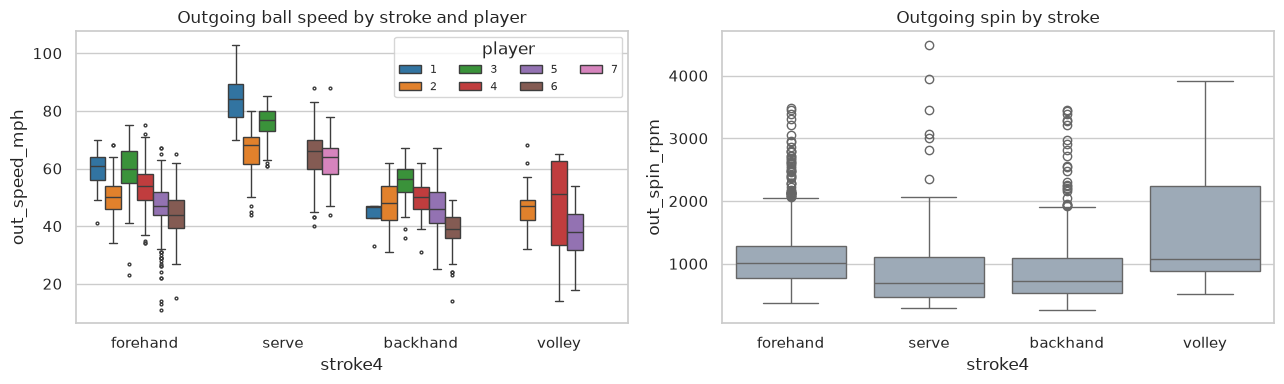

In [2]:
display(pd.crosstab(shots.player_id, shots.stroke, margins=True))

lab = shots.assign(out_speed_mph=shots.out_speed_mph.where(shots.out_speed_mph > 0),
                   out_spin_rpm=shots.out_spin_rpm.where(shots.out_spin_rpm > 0))
print("Label coverage (0 = not recorded by PlaySight):")
display(shots.groupby("stroke", observed=True)[["out_speed_mph", "out_spin_rpm", "in_speed_mph", "in_spin_rpm"]]
             .agg(lambda s: (s > 0).mean()).style.format("{:.0%}"))

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=lab, x="stroke4", y="out_speed_mph", hue="player_id", ax=axs[0], palette="tab10", fliersize=2)
axs[0].set_title("Outgoing ball speed by stroke and player"); axs[0].legend(title="player", ncol=4, fontsize=8)
sns.boxplot(data=lab, x="stroke4", y="out_spin_rpm", ax=axs[1], color="#9ab")
axs[1].set_title("Outgoing spin by stroke")
plt.tight_layout()

## 2. Impact detection and stroke templates

Ball impact shows up as a sharp spike in the accelerometer. The impact sample is taken as the peak of
the acceleration jerk ‖Δa‖·fs. Saturation matters here: hard swings clip both sensors.

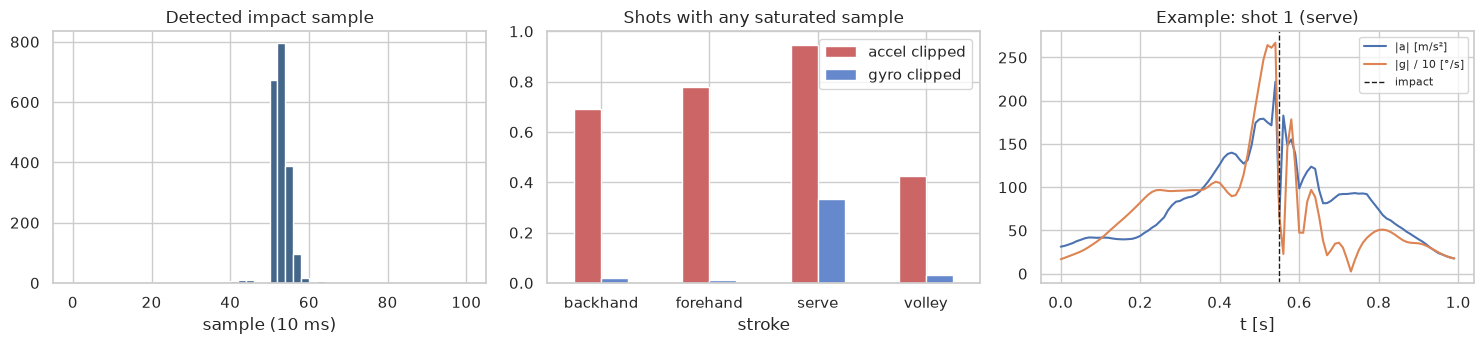

In [3]:
a, g = X[:, :, :3], X[:, :, 3:]
a_mag, g_mag = np.linalg.norm(a, axis=2), np.linalg.norm(g, axis=2)
jerk = np.linalg.norm(np.diff(a, axis=1), axis=2) * FS
impact = jerk.argmax(axis=1) + 1
shots["impact_idx"] = impact

fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
axs[0].hist(impact, bins=np.arange(0, 101, 2), color="#468")
axs[0].set(title="Detected impact sample", xlabel="sample (10 ms)")
sat = pd.DataFrame({"stroke": shots.stroke4,
                    "accel clipped": (np.abs(a) >= ACC_SAT).any(axis=(1, 2)),
                    "gyro clipped": (np.abs(g) >= GYRO_SAT).any(axis=(1, 2))})
sat.groupby("stroke").mean().plot.bar(ax=axs[1], rot=0, color=["#c66", "#68c"])
axs[1].set(title="Shots with any saturated sample", ylim=(0, 1))

# Example shot
i = int(shots.index[shots.stroke == "serve"][0])
t = np.arange(100) / FS
axs[2].plot(t, a_mag[i], label="|a| [m/s²]")
axs[2].plot(t, g_mag[i] / 10, label="|g| / 10 [°/s]")
axs[2].axvline(impact[i] / FS, color="k", ls="--", lw=1, label="impact")
axs[2].set(title=f"Example: shot {i} (serve)", xlabel="t [s]"); axs[2].legend(fontsize=8)
plt.tight_layout()

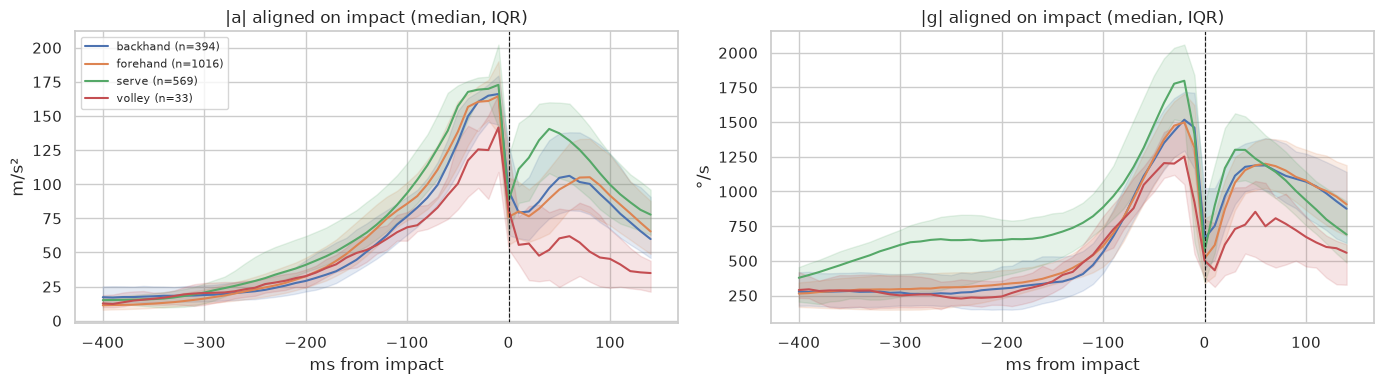

In [4]:
# Mean |a| and |g| per stroke type, aligned on impact (-400 ms .. +150 ms)
PRE, POST = 40, 15
rel_t = np.arange(-PRE, POST) * 1000 / FS
fig, axs = plt.subplots(1, 2, figsize=(14, 4), sharex=True)
for stroke, idx in shots.groupby("stroke4").groups.items():
    segs_a, segs_g = [], []
    for k, i in zip(impact[idx], idx):
        if k - PRE >= 0 and k + POST <= 100:
            segs_a.append(a_mag[i, k - PRE:k + POST]); segs_g.append(g_mag[i, k - PRE:k + POST])
    for ax, segs in ((axs[0], segs_a), (axs[1], segs_g)):
        s = np.array(segs)
        line, = ax.plot(rel_t, np.median(s, 0), label=f"{stroke} (n={len(s)})")
        ax.fill_between(rel_t, *np.percentile(s, [25, 75], axis=0), alpha=0.15, color=line.get_color())
axs[0].set(title="|a| aligned on impact (median, IQR)", xlabel="ms from impact", ylabel="m/s²")
axs[1].set(title="|g| aligned on impact (median, IQR)", xlabel="ms from impact", ylabel="°/s")
for ax in axs: ax.axvline(0, color="k", lw=0.8, ls="--")
axs[0].legend(fontsize=8)
plt.tight_layout()

## 3. Feature engineering

Per-shot features, mostly relative to the detected impact:

| feature | meaning |
|---|---|
| `gyro_at_impact`, `g{x,y,z}_at_impact` | angular speed over the 50 ms before impact (racket-head speed proxy) |
| `acc_at_impact`, `a{x,y,z}_at_impact` | acceleration over the 50 ms before impact (centripetal + swing) |
| `gyro_drop` | loss of angular speed across impact (momentum transferred to the ball) |
| `jerk_peak` | impact shock strength |
| `swing_energy` | ∫‖g‖² over the 300 ms before impact |
| `gyro_peak`, `acc_peak`, `g{x,y,z}_absmax` | window maxima |
| `gyro_peak_lead_ms` | how long before impact peak angular speed happened |
| `acc_sat_frac`, `gyro_sat_frac` | fraction of samples clipped at full scale |
| `windup_gyro`, `a{x,y,z}_windup` | mean ‖g‖ and acceleration vector 400–200 ms before impact (wind-up phase / racket orientation) |
| `swept_{x,y,z}` | rotation angle swept about each axis in the 300 ms before impact (°) |

In [5]:
def shot_features(x: np.ndarray, k: int) -> dict:
    a, g = x[:, :3], x[:, 3:]
    am, gm = np.linalg.norm(a, axis=1), np.linalg.norm(g, axis=1)
    jerk = np.linalg.norm(np.diff(a, axis=0), axis=1) * FS
    pre = slice(max(k - 30, 0), max(k, 1))
    pre5 = slice(max(k - 5, 0), max(k, 1))
    post5 = slice(min(k + 1, 99), min(k + 6, 100))
    f = {
        "gyro_at_impact": gm[pre5].mean(),
        "acc_at_impact": am[pre5].mean(),
        "gyro_drop": gm[pre5].mean() - gm[post5].mean(),
        "jerk_peak": jerk.max(),
        "swing_energy": (gm[pre] ** 2).sum() / FS,
        "gyro_peak": gm.max(),
        "acc_peak": am.max(),
        "gyro_peak_lead_ms": (k - gm.argmax()) * 1000 / FS,
        "acc_sat_frac": (np.abs(a) >= ACC_SAT).mean(),
        "gyro_sat_frac": (np.abs(g) >= GYRO_SAT).mean(),
    }
    wind = slice(max(k - 40, 0), max(k - 20, 1))
    f["windup_gyro"] = gm[wind].mean()
    for j, c in enumerate("xyz"):
        f[f"a{c}_windup"] = a[wind, j].mean()
        f[f"swept_{c}"] = g[pre, j].sum() / FS
        f[f"g{c}_at_impact"] = g[pre5, j].mean()
        f[f"a{c}_at_impact"] = a[pre5, j].mean()
        f[f"g{c}_absmax"] = np.abs(g[:, j]).max()
    return f

F = pd.DataFrame([shot_features(X[i], impact[i]) for i in range(len(shots))])
FEATURES = list(F.columns)
df = pd.concat([shots, F], axis=1)
F.describe().T[["mean", "std", "min", "50%", "max"]]

,mean,std,min,50%,max
gyro_at_impact,1.414e+03,300.596,342.699,1401.204,2550.853
acc_at_impact,1.531e+02,25.251,27.387,156.637,227.248
gyro_drop,3.662e+02,349.376,-896.700,367.497,2420.514
jerk_peak,1.552e+04,4767.119,5524.307,14995.231,34696.545
swing_energy,2.116e+05,112339.376,18411.832,179920.874,668154.018
gyro_peak,1.725e+03,324.630,893.544,1727.989,2863.758
acc_peak,1.805e+02,27.398,65.100,178.546,271.580
gyro_peak_lead_ms,3.358e+00,39.323,-220.000,20.000,290.000
acc_sat_frac,1.327e-02,0.016,0.000,0.010,0.350
gyro_sat_frac,6.259e-04,0.002,0.000,0.000,0.033


## 4. Which features track ball speed and spin?

Spearman rank correlation (robust to the saturation non-linearity), computed separately for serves and for
groundstrokes, using only shots where PlaySight recorded the target.

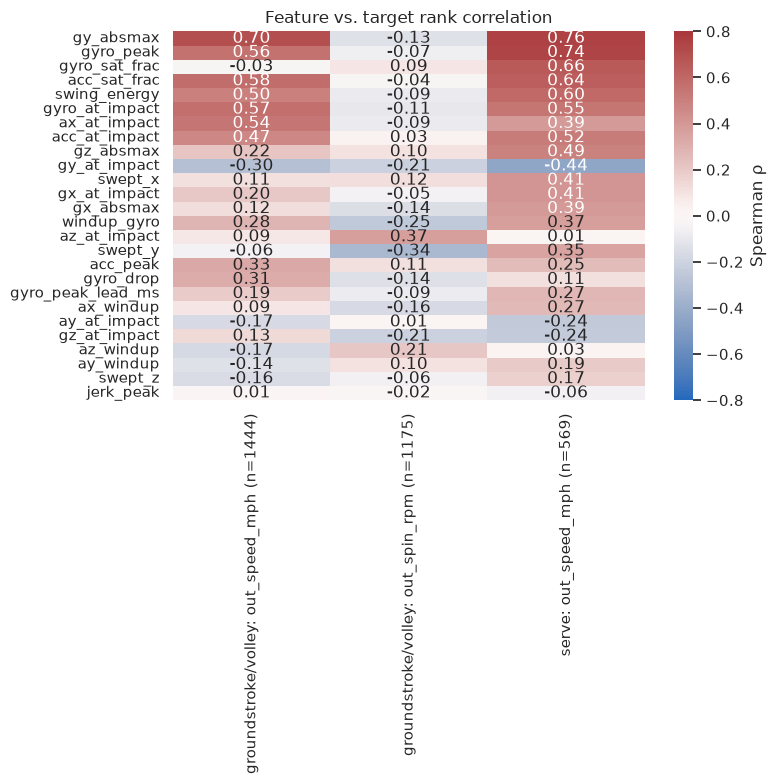

In [6]:
rows = []
for grp, target in [("serve", "out_speed_mph"), ("groundstroke/volley", "out_speed_mph"),
                    ("groundstroke/volley", "out_spin_rpm")]:
    sub = df[(df.group == grp) & (df[target] > 0)]
    for feat in FEATURES:
        r, p = spearmanr(sub[feat], sub[target])
        rows.append(dict(target=f"{grp}: {target} (n={len(sub)})", feature=feat, rho=r, p=p))
corr = pd.DataFrame(rows)
mat = corr.pivot(index="feature", columns="target", values="rho")
mat = mat.reindex(mat.abs().max(axis=1).sort_values(ascending=False).index)

fig, ax = plt.subplots(figsize=(8, 8))
sns.heatmap(mat, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-0.8, vmax=0.8, ax=ax, cbar_kws={"label": "Spearman ρ"})
ax.set(title="Feature vs. target rank correlation", xlabel="", ylabel="")
plt.tight_layout()

{'serve': 'gy_absmax', 'groundstroke/volley': 'gy_absmax'}


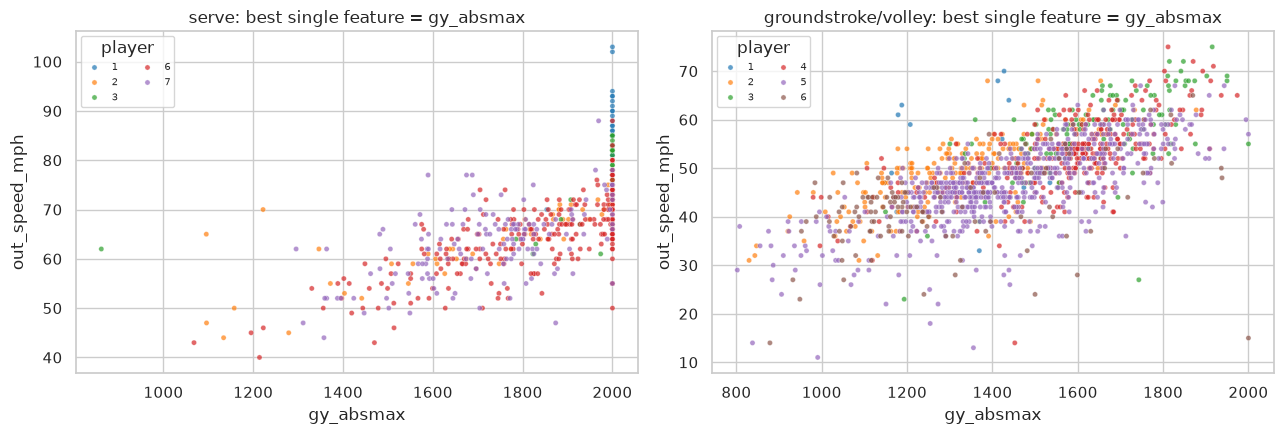

In [7]:
# Strongest single features, scatter vs. outgoing speed
top = {grp: mat[[c for c in mat.columns if c.startswith(grp) and "speed" in c][0]].abs().idxmax()
       for grp in ["serve", "groundstroke/volley"]}
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (grp, feat) in zip(axs, top.items()):
    sub = df[(df.group == grp) & (df.out_speed_mph > 0)]
    sns.scatterplot(data=sub, x=feat, y="out_speed_mph", hue="player_id", palette="tab10", s=14, ax=ax, alpha=0.7)
    ax.set_title(f"{grp}: best single feature = {feat}")
    ax.legend(title="player", fontsize=7, ncol=2)
plt.tight_layout()
print(top)

## 5. Ball speed regression, leave-one-subject-out

Each player is held out in turn and the model is trained on the others, so the score reflects a new user.
Models compared:
- **mean**: predicts the training players' mean speed;
- **ridge (1 feature)**: linear model on the best single feature;
- **ridge (all)**: linear model on all features;
- **random forest (all)**: tree model on all features.

The TennisEye paper evaluates the same way: serves use players 1, 2, 3, 6, 7, and groundstrokes use players 2–6.
Here every player with labelled shots is included.

In [8]:
logo = LeaveOneGroupOut()

def loso_regression(sub: pd.DataFrame, target: str, best_feat: str):
    models = {
        "mean": (lambda: DummyRegressor(), FEATURES),
        "ridge (1 feature)": (lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20))), [best_feat]),
        "ridge (all)": (lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20))), FEATURES),
        "random forest (all)": (lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=0), FEATURES),
    }
    y, groups = sub[target].to_numpy(), sub.player_id.to_numpy()
    res, preds, imps = [], {}, []
    for name, (make, cols) in models.items():
        Xs = sub[cols].to_numpy()
        pred = np.empty_like(y, dtype=float)
        for tr, te in logo.split(Xs, y, groups):
            m = make().fit(Xs[tr], y[tr])
            pred[te] = m.predict(Xs[te])
            if name == "random forest (all)":
                pi = permutation_importance(m, Xs[te], y[te], n_repeats=5, random_state=0,
                                            scoring="neg_mean_absolute_error")
                imps.append(pi.importances_mean)
            res.append(dict(model=name, held_out_player=groups[te][0], n=len(te),
                            mae=mean_absolute_error(y[te], pred[te])))
        preds[name] = pred
    res = pd.DataFrame(res)
    summary = res.groupby("model").apply(lambda d: pd.Series({
        "MAE mph (pooled)": np.average(d.mae, weights=d.n),
        "MAE mph (worst player)": d.mae.max()}), include_groups=False).sort_values("MAE mph (pooled)")
    imp = pd.Series(np.mean(imps, axis=0), index=FEATURES).sort_values(ascending=False)
    return summary, res, preds, imp

reg = {}
for grp in ["serve", "groundstroke/volley"]:
    sub = df[(df.group == grp) & (df.out_speed_mph > 0)].reset_index(drop=True)
    reg[grp] = (sub, *loso_regression(sub, "out_speed_mph", top[grp]))
    print(f"\n=== {grp}: {len(sub)} shots, {sub.player_id.nunique()} players, "
          f"speed {sub.out_speed_mph.mean():.1f} ± {sub.out_speed_mph.std():.1f} mph")
    display(reg[grp][1])


=== serve: 569 shots, 5 players, speed 66.7 ± 9.3 mph


,MAE mph (pooled),MAE mph (worst player)
model,,
random forest (all),5.239,10.871
ridge (1 feature),5.358,12.947
ridge (all),7.267,11.386
mean,7.560,18.341



=== groundstroke/volley: 1444 shots, 6 players, speed 49.0 ± 8.8 mph


,MAE mph (pooled),MAE mph (worst player)
model,,
ridge (1 feature),5.114,12.213
random forest (all),5.451,12.962
ridge (all),5.815,10.818
mean,7.293,10.668


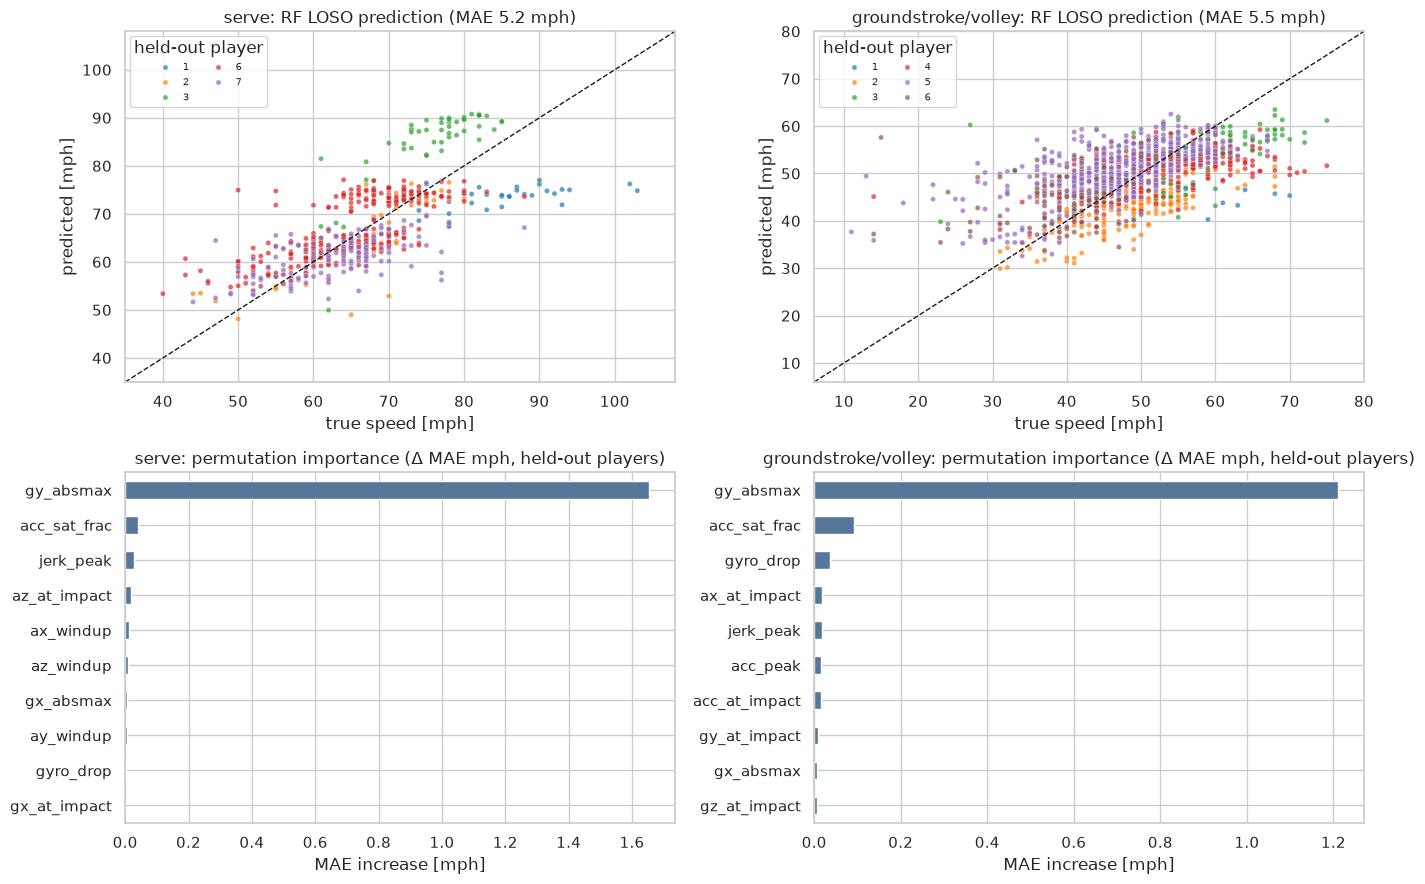

In [9]:
fig, axs = plt.subplots(2, 2, figsize=(14, 9))
for col, grp in enumerate(reg):
    sub, summary, res, preds, imp = reg[grp]
    ax = axs[0, col]
    pred = preds["random forest (all)"]
    sns.scatterplot(x=sub.out_speed_mph, y=pred, hue=sub.player_id, palette="tab10", s=14, alpha=0.7, ax=ax)
    lim = [sub.out_speed_mph.min() - 5, sub.out_speed_mph.max() + 5]
    ax.plot(lim, lim, "k--", lw=1)
    ax.set(title=f"{grp}: RF LOSO prediction (MAE {summary.loc['random forest (all)', 'MAE mph (pooled)']:.1f} mph)",
           xlabel="true speed [mph]", ylabel="predicted [mph]", xlim=lim, ylim=lim)
    ax.legend(title="held-out player", fontsize=7, ncol=2)
    imp.head(10)[::-1].plot.barh(ax=axs[1, col], color="#579")
    axs[1, col].set(title=f"{grp}: permutation importance (Δ MAE mph, held-out players)", xlabel="MAE increase [mph]")
plt.tight_layout()

## 6. Stroke type classification, leave-one-subject-out

Four classes: serve, forehand, backhand and volley (forehand and backhand volleys merged).

LOSO accuracy 54.6%, macro-F1 0.43


,1,2,3,4,5,6,7
accuracy,1.0,0.652,0.704,0.209,0.829,0.323,0.007


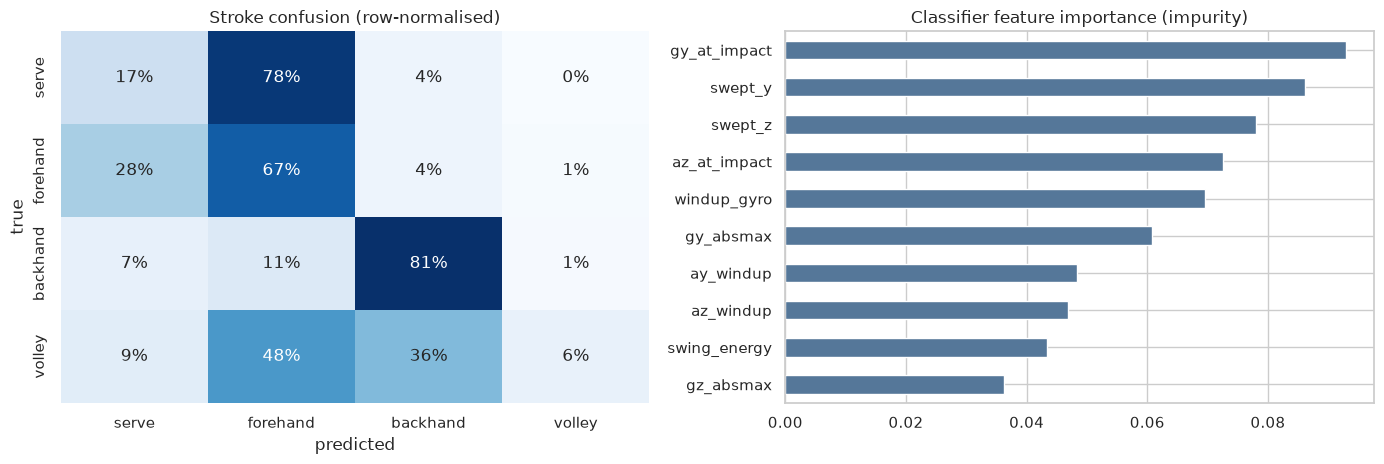

In [10]:
y = df.stroke4.to_numpy()
groups = df.player_id.to_numpy()
Xs = df[FEATURES].to_numpy()
pred = np.empty_like(y)
imps = []
for tr, te in logo.split(Xs, y, groups):
    clf = RandomForestClassifier(n_estimators=400, class_weight="balanced", n_jobs=-1, random_state=0).fit(Xs[tr], y[tr])
    pred[te] = clf.predict(Xs[te])
    imps.append(clf.feature_importances_)

labels = ["serve", "forehand", "backhand", "volley"]
acc = (pred == y).mean()
macro_f1 = f1_score(y, pred, average="macro")
per_player = pd.Series({p: (pred[groups == p] == y[groups == p]).mean() for p in np.unique(groups)}, name="accuracy")
print(f"LOSO accuracy {acc:.1%}, macro-F1 {macro_f1:.2f}")
display(per_player.to_frame().T)

fig, axs = plt.subplots(1, 2, figsize=(14, 4.8))
cm = confusion_matrix(y, pred, labels=labels, normalize="true")
sns.heatmap(cm, annot=True, fmt=".0%", xticklabels=labels, yticklabels=labels, cmap="Blues", ax=axs[0], cbar=False)
axs[0].set(title="Stroke confusion (row-normalised)", xlabel="predicted", ylabel="true")
pd.Series(np.mean(imps, 0), index=FEATURES).sort_values().tail(10).plot.barh(ax=axs[1], color="#579")
axs[1].set(title="Classifier feature importance (impurity)")
plt.tight_layout()


## 7. Findings

**Signals and impact**
- Each window is centred on the ball strike. Impact (the peak of acceleration jerk) falls at sample 50–55 in almost every shot.
  At impact, rotation rate drops sharply (momentum passed to the ball) and acceleration spikes.
- **Saturation is everywhere:** the accelerometer clips at 16 g in about 94% of serves and 70–78% of groundstrokes, and the gyro
  clips in about 33% of serves. Peak-amplitude features therefore hit a ceiling on the hardest shots. This is why TennisEye
  interpolates clipped `gy` samples (`two_side_interpolation_gy.m`).

**What tracks ball speed** (Spearman ρ)
- **`gy_absmax`**, peak rotation about the handle's Y axis (the main swing axis), is the best single feature:
  ρ = 0.76 for serves and 0.70 for groundstrokes. Swing energy and rotation rate at impact follow it.
  The saturation-fraction features correlate too, because clipping is itself a sign of a hard swing.
- **Spin** (groundstrokes) correlates only weakly with any feature. The best are `az_at_impact` (ρ = 0.37) and `swept_y` (ρ = −0.34),
  which fits the idea that spin comes from the racket's brushing angle rather than swing speed.

**Leave-one-player-out ball speed** (mean absolute error, mph)
| | always predict mean | 1-feature linear model | random forest |
|---|---|---|---|
| serve (66.7 ± 9.3 mph) | 7.6 | 5.4 | **5.2** |
| groundstroke/volley (49.0 ± 8.8 mph) | 7.3 | **5.1** | 5.5 |

- Adding features beyond `gy_absmax` barely helps: permutation importance is almost entirely that one feature.
- **Per-player offsets dominate the error.** Player 3's serves are over-predicted by about 10 mph and player 1's under-predicted.
  The swing-to-ball-speed relationship depends on the player (racket, string tension, sensor mounting, technique),
  so a short per-user calibration would likely help more than more features.

**Stroke type (leave-one-player-out)**: 55% accuracy, macro-F1 0.43
- **Forehand vs. backhand** is easy: the sign of `gy` at impact flips between them consistently for every player.
- **Serve vs. forehand** fails across players: 67% of serves are predicted as forehands. Serves and forehands rotate the handle
  the same way, and the class balance is confounded with player. Player 7 hit only serves and players 4 and 5 hit none,
  so the model partly learns "who" instead of "what". Wind-up and orientation features did not fix this, so it would need
  the full time series (e.g. a 1D CNN on the raw window) or within-player training data.
